# LEGEND poster — reproducible analysis workbench

**Provisional physics benchmark.** Run `poster_setup.ipynb` to change and save
assumptions, then run this notebook. Physics comes from existing WIMP-LEGEND
APIs. Figures consume saved numerical outputs, not pilot sensitivity tables.

The original notebook is preserved byte-for-byte at
[historical/poster_workbench_pilot.ipynb](historical/poster_workbench_pilot.ipynb).
Its assets are historical references, not validated predictions.


In [26]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd().resolve()
while not (ROOT / 'pyproject.toml').exists():
    if ROOT.parent == ROOT:
        raise RuntimeError('Open this notebook inside the WIMP-LEGEND checkout')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))
from IPython.display import display, Image
from analyses.legend_poster import load_config, save_config, validate_config, resolve_profile
CONFIG_PATH = Path(os.environ.get('WIMP_POSTER_CONFIG', ROOT / 'analyses/legend_poster/config.json'))
print('Configuration:', CONFIG_PATH)


Configuration: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\config.json


## Load the saved configuration

In [27]:
configuration = load_config(CONFIG_PATH)
profile = os.environ.get('WIMP_POSTER_PROFILE', configuration['execution']['default_profile'])
resolved = resolve_profile(configuration, profile)
print(resolved['status'])
print('Profile:', resolved['execution']['resolved_label'])
display(resolved['analysis'])
display(resolved['provenance']['notes'])


PROVISIONAL LEGEND BENCHMARK; not a validated prediction
Profile: standard


{'scenarios': ['natural_AAr', 'enriched_UAr', 'legend_poster'],
 'exposures_kg_day': [365.25, 3652.5, 36525.0],
 'confidence_level': 0.9,
 'roi': {'method': 'threshold_anchored',
  'signal_fraction': 0.95,
  'normalization': 'signal inside configured observed analysis window'},
 'methods': ['poisson_cls_counting'],
 'days_per_year': 365.25,
 'provenance': 'Known background median exact Poisson CLs; optional binned_asimov explicitly asymptotic, not an exact alternative',
 'binned_roi': 'full_analysis_window'}

['No physical source uncertainty propagation or LEGEND calibration.',
 'Natural isotope central abundances and atomic masses from frozen NIST snapshot; enriched composition explicitly hypothetical.',
 'Nuclear Ge response source closure deficits and unknown physical validity range retained.',
 'Background physical source data and hashes inherited unchanged from BG-BENCHMARK-001.']

## Target mixtures and coefficient conventions

Rates are computed for each isotope with the accepted AFH datasets and combined
with the configured mixture's **bulk mass weights**. Bare masses enter
kinematics; neutral atomic masses enter per-kg detector counts. Solar CEvNS is
also summed isotope by isotope; solar ES uses the exact total Ge atom count.

O1 uses the physical proton SI adapter. O8/O11 are single-operator limits on
`|c_i^p|` in GeV^-2 with the saved spin and neutron/proton ratio. They are **not
SI cross sections**. The frozen half-isospin convention is unchanged.


In [28]:
from analyses.legend_poster.models import isotope_weights
for name in resolved['target']['presets']:
    print(name)
    display(isotope_weights(resolved, name))
display({k: resolved['signal'][k] for k in ('convention_id','j_chi','fn_over_fp',
    'coefficient_unit','sigma_p_ref_cm2','coefficient_ref_GeV_minus2','m_N_reference_GeV')})


natural


{70: {'number_fraction': 0.2057,
  'nuclear_mass_fraction': 0.19804170687851452,
  'bulk_mass_fraction': 0.19804355145202948,
  'targets_per_kg': 1.7056259645527543e+24,
  'pure_targets_per_kg': 8.612378196852799e+24},
 72: {'number_fraction': 0.2745,
  'nuclear_mass_fraction': 0.2718329768127494,
  'bulk_mass_fraction': 0.2718336191909213,
  'targets_per_kg': 2.276102709138216e+24,
  'pure_targets_per_kg': 8.373146470671107e+24},
 73: {'number_fraction': 0.0775,
  'nuclear_mass_fraction': 0.07781583684459206,
  'bulk_mass_fraction': 0.07781576077225202,
  'targets_per_kg': 6.42615518973449e+23,
  'pure_targets_per_kg': 8.258166630976337e+24},
 74: {'number_fraction': 0.365,
  'nuclear_mass_fraction': 0.3715028742763129,
  'bulk_mass_fraction': 0.3715013079965335,
  'targets_per_kg': 3.0265117990362435e+24,
  'pure_targets_per_kg': 8.146705634383618e+24},
 76: {'number_fraction': 0.0773,
  'nuclear_mass_fraction': 0.08080660518783112,
  'bulk_mass_fraction': 0.08080576058826378,
  'tar

enriched_provisional


{70: {'number_fraction': 0.0,
  'nuclear_mass_fraction': 0.0,
  'bulk_mass_fraction': 0.0,
  'targets_per_kg': 0.0,
  'pure_targets_per_kg': 8.612378196852799e+24},
 72: {'number_fraction': 0.0,
  'nuclear_mass_fraction': 0.0,
  'bulk_mass_fraction': 0.0,
  'targets_per_kg': 0.0,
  'pure_targets_per_kg': 8.373146470671107e+24},
 73: {'number_fraction': 0.0,
  'nuclear_mass_fraction': 0.0,
  'bulk_mass_fraction': 0.0,
  'targets_per_kg': 0.0,
  'pure_targets_per_kg': 8.258166630976337e+24},
 74: {'number_fraction': 0.08,
  'nuclear_mass_fraction': 0.07805639036827085,
  'bulk_mass_fraction': 0.07805683914106132,
  'targets_per_kg': 6.3590609123266e+23,
  'pure_targets_per_kg': 8.146705634383618e+24},
 76: {'number_fraction': 0.92,
  'nuclear_mass_fraction': 0.9219436096317292,
  'bulk_mass_fraction': 0.9219431608589387,
  'targets_per_kg': 7.31292004917559e+24,
  'pure_targets_per_kg': 7.932072561135358e+24}}

{'convention_id': 'anand2014_prc89_065501_half_isospin_v1',
 'j_chi': 0.5,
 'fn_over_fp': 1.0,
 'coefficient_unit': 'GeV^-2',
 'sigma_p_ref_cm2': 1e-42,
 'coefficient_ref_GeV_minus2': 1e-05,
 'm_N_reference_GeV': 0.93827208943}

## Run or reuse numerical outputs

The first run evaluates core recoil rates, integrates every observed-energy bin,
and checks refinement. The disk cache is keyed by physics inputs, source hashes,
software versions and numerical settings. Exposure and plot-only edits reuse
expensive source calculations. No pickle cache is used. A failed convergence
check raises instead of producing an accepted result.


In [29]:
from analyses.legend_poster import run_analysis
run = run_analysis(configuration, profile=profile,
    cache_dir=os.environ.get('WIMP_POSTER_CACHE'),
    output_dir=os.environ.get('WIMP_POSTER_RUNS'))
print('Saved run:', run['path'])
print('Run ID:', run['manifest']['run_id'])
print('Code commit:', run['manifest']['source']['git_commit'])
print('Cache hits/misses:', run['manifest']['cache']['hits'], run['manifest']['cache']['misses'])


Saved run: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\runs\db98e4db2092c27c8a25
Run ID: db98e4db2092c27c8a25f5a50626972405a130d54129e8b6849d959c8c898d99
Code commit: 105e19cdd591546f47a155c620ede1ef13280e29
Cache hits/misses: 2 456


## Component spectra and threshold features

Rates below are integrated counts divided by each bin's own width, in
`events/(kg year keV observed)`. Lines use detector bin probabilities; truth
continua are reintegrated. Already-observed inputs are never refolded.

The next cell reloads only saved arrays and current plotting settings, so it
can be rerun after styling edits without recomputing physics.


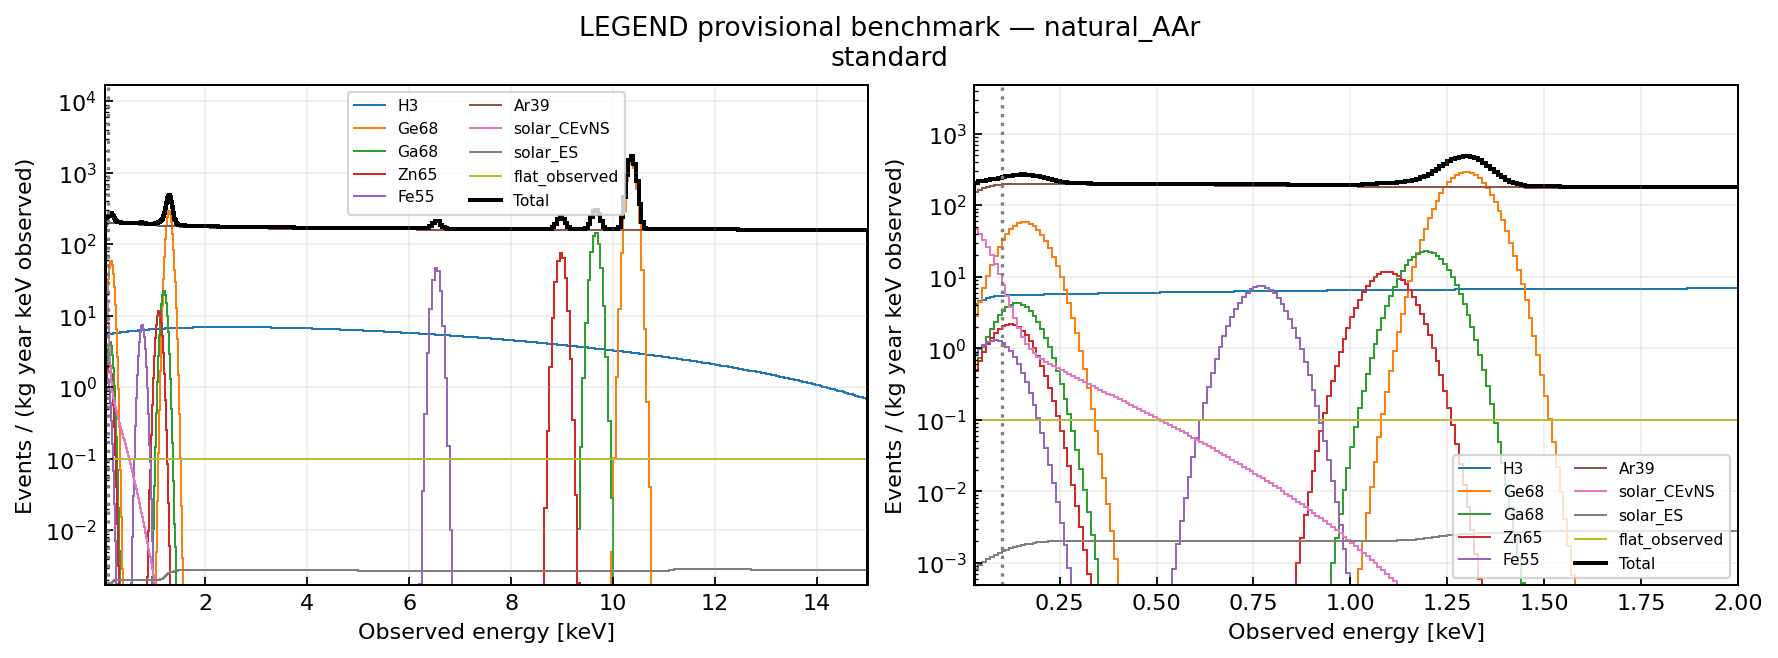

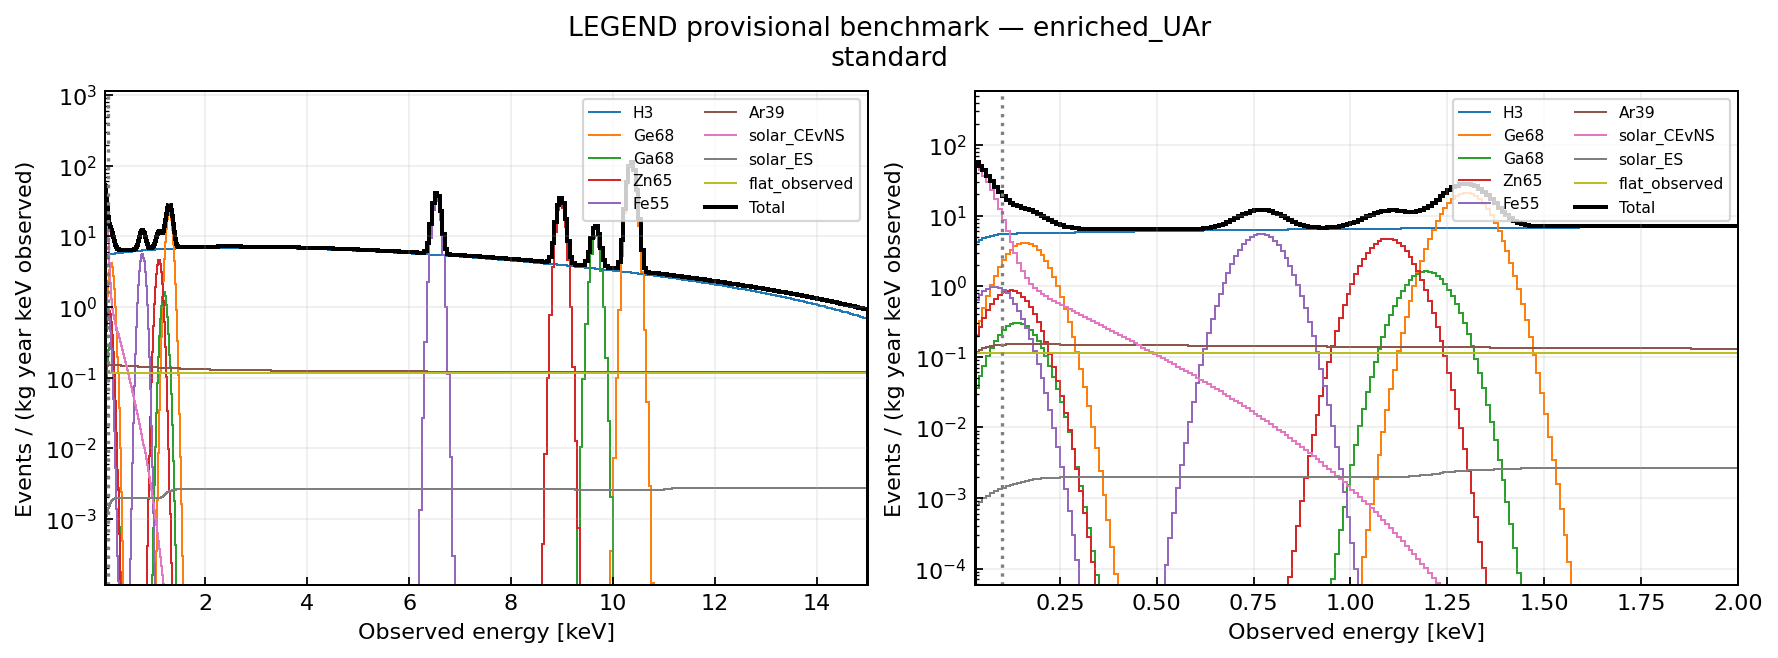

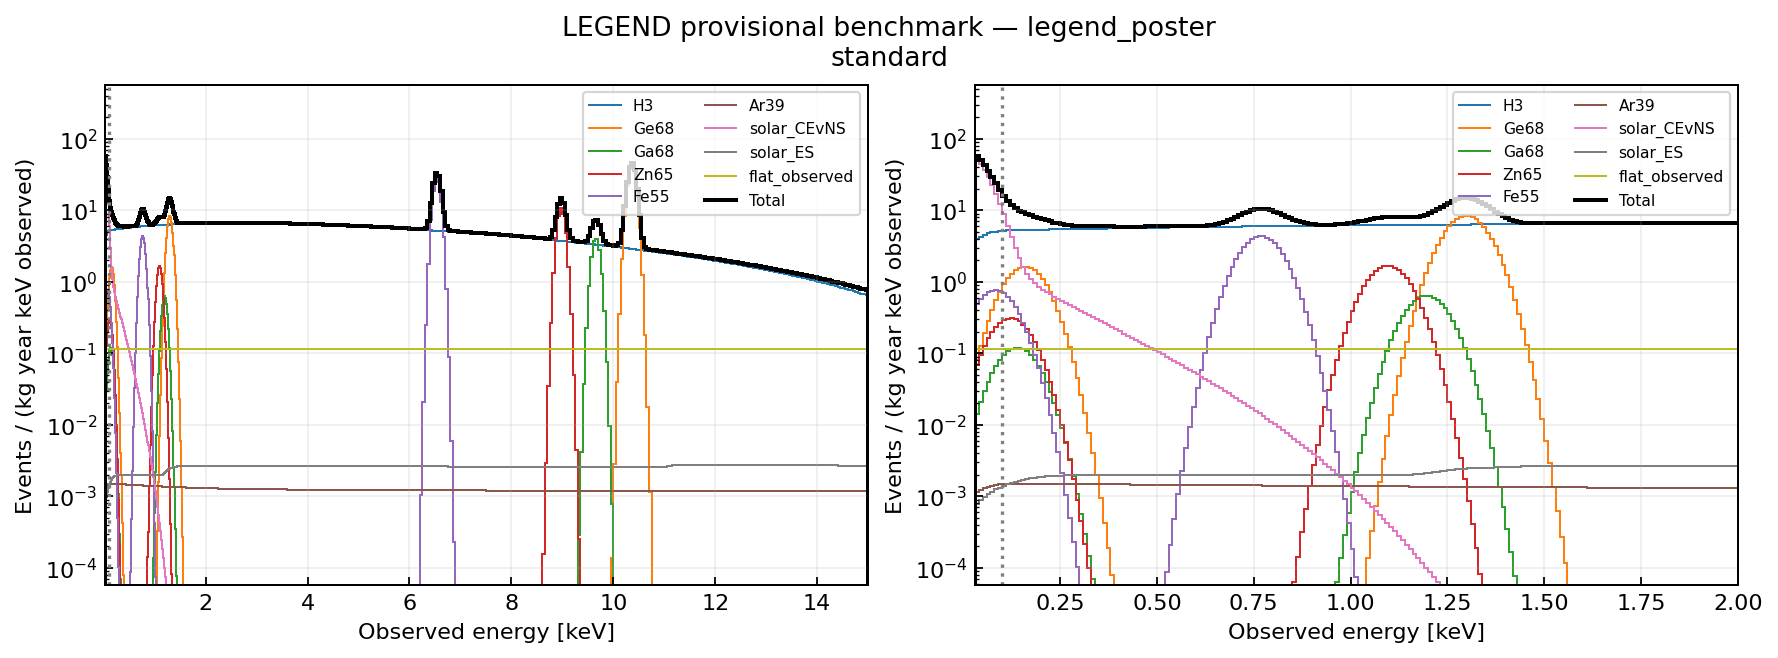

In [30]:
from analyses.legend_poster.plotting import plot_run
plot_style = load_config(CONFIG_PATH)['plotting']
figures = plot_run(run, plotting=plot_style)
for scenario in run['manifest']['resolved_configuration']['analysis']['scenarios']:
    display(Image(filename=str(run['path'] / 'figures' / ('background_' + scenario + '.png'))))


## SI and NREFT sensitivities

Counting limits use a threshold-anchored ROI containing at least 95% of the
signal **inside the configured observed window**, then median exact known-B
Poisson CLs at the saved confidence level. ROI edges are saved per mass/operator.
SI scales as `sigma_upper = mu_upper * sigma_ref`; single-operator coefficients
scale as `|c_upper| = sqrt(mu_upper) * |c_ref|`.

Optional `binned_asimov` uses the separate asymptotic profile backend over the
full above-threshold window; it is neither exact CLs nor a sparse-count coverage
claim. External curves retain their own confidence/construction assumptions and
are frozen snapshots, not guaranteed latest 2026 exclusions. Projections are dashed.


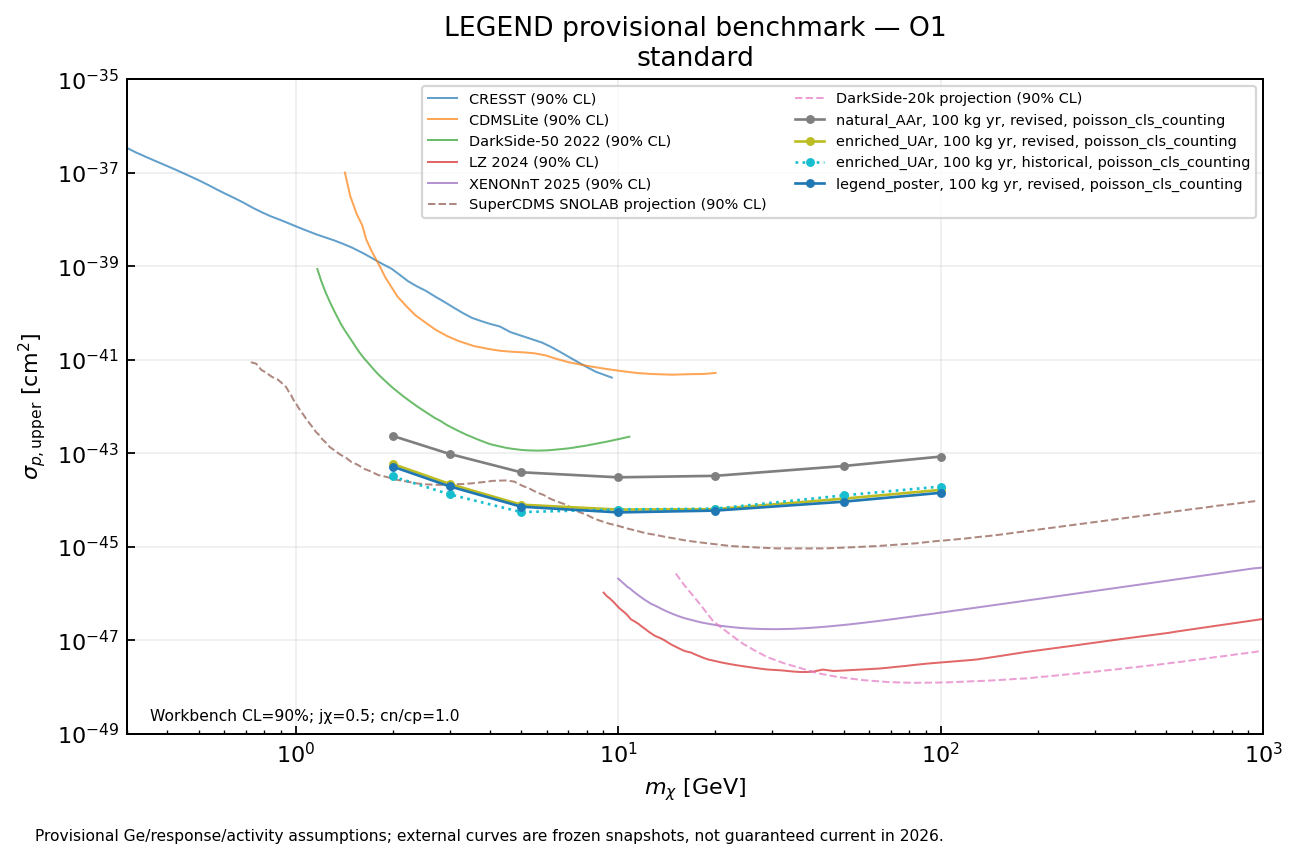

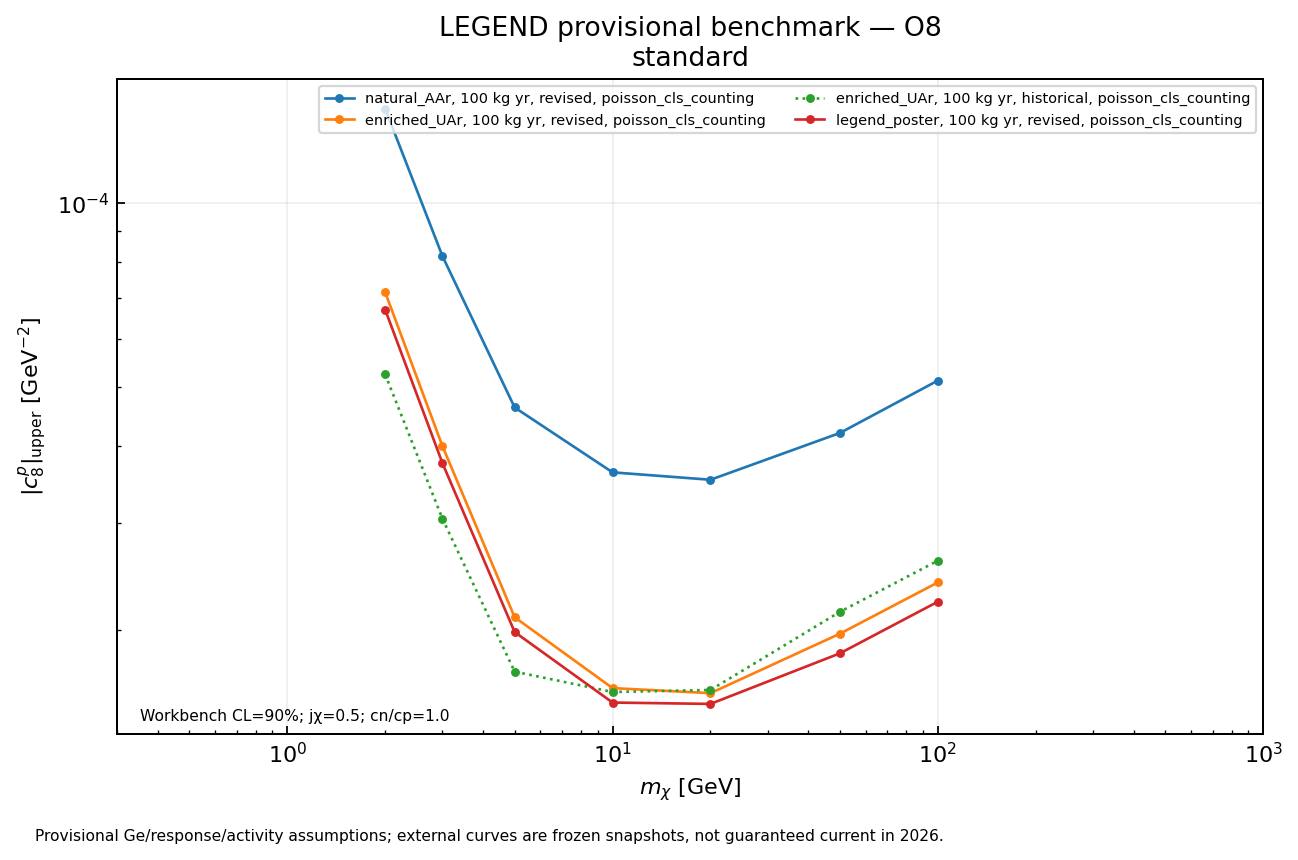

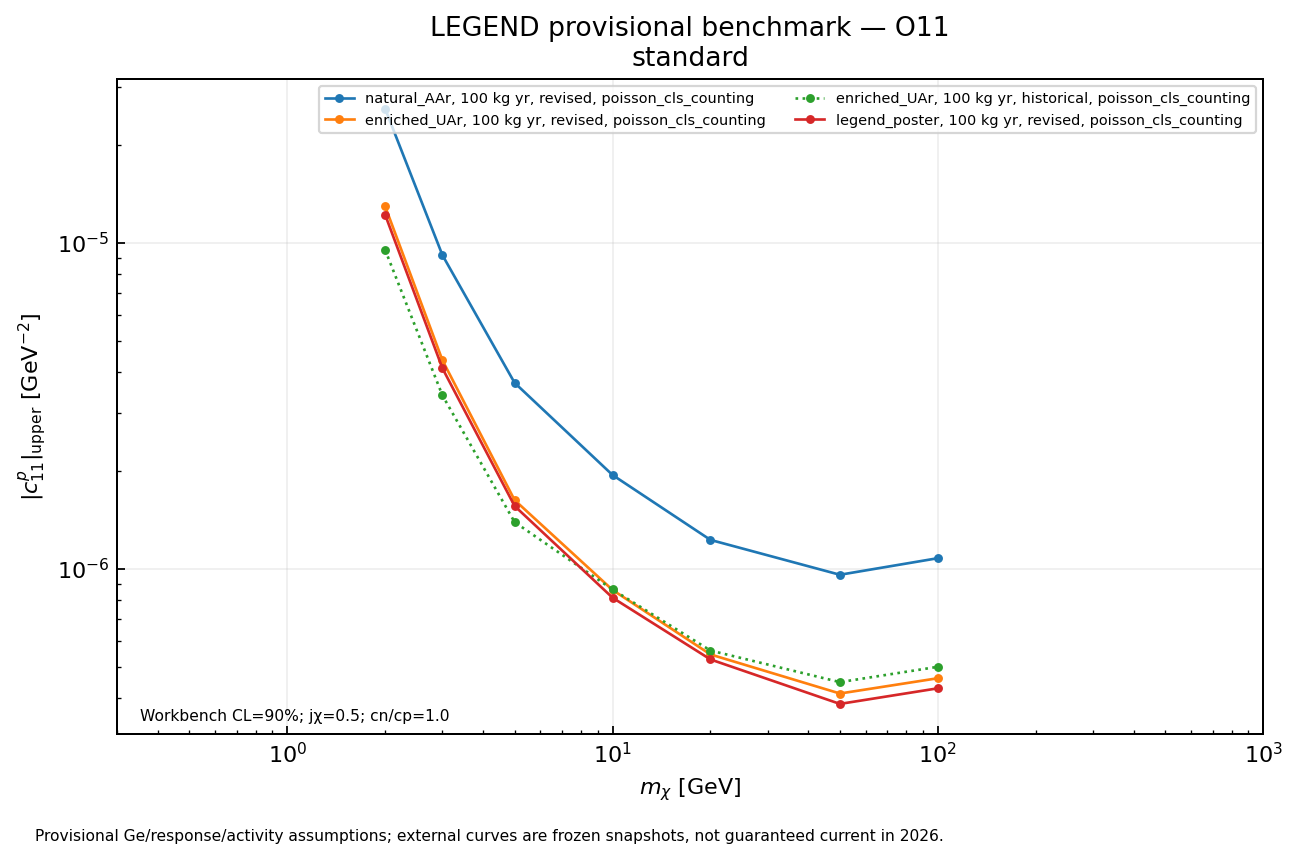

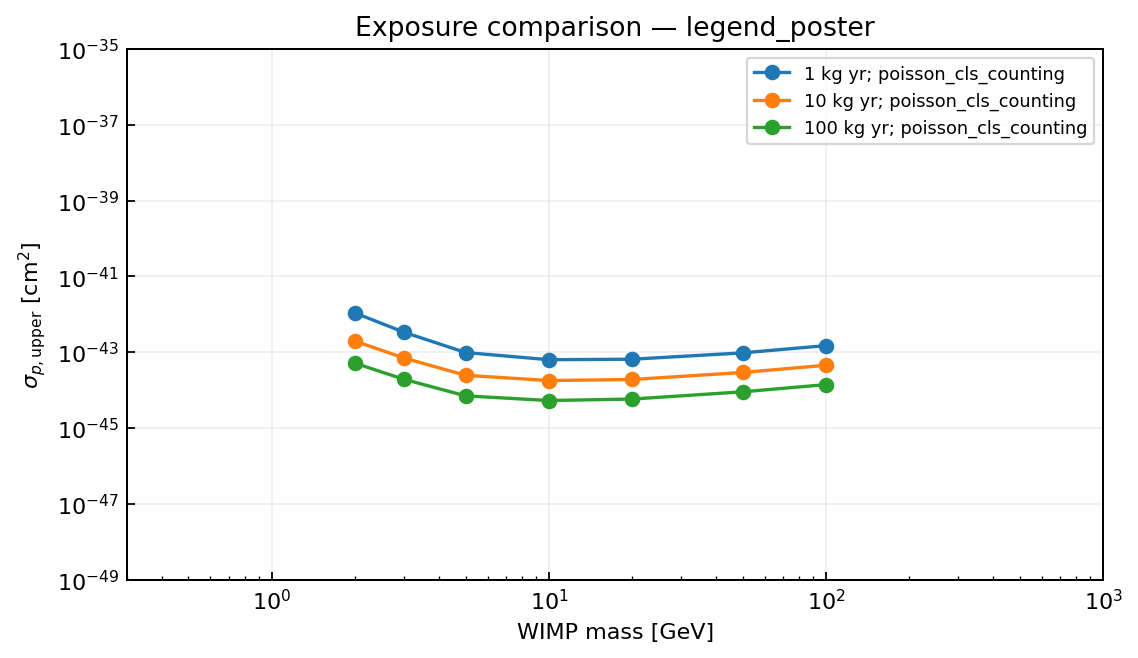

[{'scenario': 'natural_AAr',
  'target': 'natural',
  'background': 'revised',
  'mass_GeV': 2.0,
  'operator': 1,
  'exposure_kg_day': 365.25,
  'method': 'poisson_cls_counting',
  'limit_value': 2.64954983780018e-42,
  'limit_unit': 'cm^2',
  'convention_id': 'anand2014_prc89_065501_half_isospin_v1',
  'roi_lower_keV': 0.1,
  'roi_upper_keV': 0.17,
  'retained_signal_fraction': 0.9641368303449557,
  'reference_signal_events': 3.074128798601224,
  'background_events': 18.433987874933642,
  'mu_upper': 2.64954983780018,
  'status': 'success',
  'confidence_level': '0.9',
  'expected_kind': 'expected_median',
  'pseudo_observed_count': '18.0',
  'statistical_notes': '["N~Poisson(B); smallest integer n with CDF(n)>=0.5"]',
  'statistical_construction': 'P(N<=n|B+mu*S) / P(N<=n|B); known B; bins collapsed',
  'statistical_approximation': 'exact discrete Poisson construction; numerical root'},
 {'scenario': 'natural_AAr',
  'target': 'natural',
  'background': 'revised',
  'mass_GeV': 2.0,

In [31]:
for operator in run['manifest']['resolved_configuration']['signal']['operators']:
    display(Image(filename=str(run['path'] / 'figures' / f'limit_O{operator}.png')))
if 1 in run['manifest']['resolved_configuration']['signal']['operators']:
    display(Image(filename=str(run['path'] / 'figures' / 'exposure_comparison.png')))
display(run['limits'][:12])


## Inspect counts, convergence and historical comparison

Historical/revised curves share the same signal, exposure, ROI and statistical
settings. The historical background is an **already-observed frozen template**:
its original response/selection is retained, not recalibrated to arbitrary new
detector assumptions. This is a count-template comparison, not a controlled
single-physics-correction measurement. The original pilot limit CSV is not used.


In [32]:
checks = run['convergence']
assert all(item['passed'] for item in checks)
print('Maximum total refinement change:', max(item['total_relative'] for item in checks))
print('Maximum significant-bin refinement change:', max(item['significant_bin_relative'] for item in checks))
display(checks[:12])
paired = resolved['background']['historical']['pair_with']
display([row for row in run['limits'] if row['scenario'] == paired][:12])
display(run['manifest']['numerical_notes'])


Maximum total refinement change: 9.834080468747433e-06
Maximum significant-bin refinement change: 0.027867731429630473


[{'scenario': 'natural_AAr',
  'component': 'H3',
  'kind': 'background',
  'total_relative': 1.833684420595849e-15,
  'significant_bin_relative': 6.69832996266395e-13,
  'passed': True},
 {'scenario': 'natural_AAr',
  'component': 'Ge68',
  'kind': 'background',
  'total_relative': 0.0,
  'significant_bin_relative': 0.0,
  'passed': True},
 {'scenario': 'natural_AAr',
  'component': 'Ga68',
  'kind': 'background',
  'total_relative': 0.0,
  'significant_bin_relative': 0.0,
  'passed': True},
 {'scenario': 'natural_AAr',
  'component': 'Zn65',
  'kind': 'background',
  'total_relative': 0.0,
  'significant_bin_relative': 0.0,
  'passed': True},
 {'scenario': 'natural_AAr',
  'component': 'Fe55',
  'kind': 'background',
  'total_relative': 0.0,
  'significant_bin_relative': 0.0,
  'passed': True},
 {'scenario': 'natural_AAr',
  'component': 'Ar39',
  'kind': 'background',
  'total_relative': 1.3207754466104949e-16,
  'significant_bin_relative': 2.8205194535162513e-15,
  'passed': True},

[{'scenario': 'enriched_UAr',
  'target': 'enriched_provisional',
  'background': 'revised',
  'mass_GeV': 2.0,
  'operator': 1,
  'exposure_kg_day': 365.25,
  'method': 'poisson_cls_counting',
  'limit_value': 1.0520361170599252e-42,
  'limit_unit': 'cm^2',
  'convention_id': 'anand2014_prc89_065501_half_isospin_v1',
  'roi_lower_keV': 0.1,
  'roi_upper_keV': 0.17,
  'retained_signal_fraction': 0.9661908150969171,
  'reference_signal_events': 3.0958460256202107,
  'background_events': 1.0394131863141018,
  'mu_upper': 1.0520361170599253,
  'status': 'success',
  'confidence_level': '0.9',
  'expected_kind': 'expected_median',
  'pseudo_observed_count': '1.0',
  'statistical_notes': '["N~Poisson(B); smallest integer n with CDF(n)>=0.5"]',
  'statistical_construction': 'P(N<=n|B+mu*S) / P(N<=n|B); known B; bins collapsed',
  'statistical_approximation': 'exact discrete Poisson construction; numerical root'},
 {'scenario': 'enriched_UAr',
  'target': 'enriched_provisional',
  'background

['All observed bins reintegrated; PCHIP used only for core truth rates.',
 'Gaussian continuum/source and batch-bin pruning at configured sigma bound; combined omitted probability <=2 Phi(-tail_sigma) per event; exact unpruned line probabilities.',
 'Per-kg normalization uses neutral atomic mass; kinematics uses derived bare nuclear masses.',
 'Solar CEvNS/ES summed over configured isotope nuclei when isotope_mixture selected.',
 '95% ROI conditional on signal inside threshold-to-upper analysis window; not full unobserved signal.',
 'Historical backgrounds already observed; no additional folding/efficiency; frozen historical response.']

## Reproducibility and remaining scientific checks

Each run contains resolved JSON, Git/source/data hashes, integrated isotope and
component counts, limit construction/units, refinement diagnostics and output
checksums. Each figure set has its own provenance/hash manifest. See
`analyses/legend_poster/README.md` and `TESTER_HANDOFF.md`.

Before publication, replace hypothetical enrichment, exposure history, LAr
transfer/veto and detector calibration; audit missing solar components
(pp/B8 only), nuclear-response validity, source mass uncertainties and CL/model
assumptions. Neither pilot nor new benchmark is a validated LEGEND prediction.
The inherited core workspace-boundary and private-cache serialization findings
remain open; this analysis neither repairs nor silently hides them.
